# Data preparation for model comparison

Target: `final_grade_pct` (regression). Predictors are grouped as continuous, discrete, or categorical.

In [40]:
import numpy as np
import pandas as pd

df = pd.read_csv('student_grade_ses_dataset.csv')
print(df.shape)

(12025, 29)


## Clean rows

Duplicates: 25 rows are exact copies, so they are removed.

Missing values: 9 columns have gaps, and 3,215 of 12,000 rows (27%) have at least one. Missingness looks random, since the final grade is about the same whether or not a value is missing. We drop those rows (complete-case analysis).

In [41]:
n_raw = len(df)
df = df.drop_duplicates().reset_index(drop=True)
n_unique = len(df)
df = df.dropna().reset_index(drop=True)
print(f'{n_raw} rows -> {n_unique} after removing duplicates -> {len(df)} after dropping rows with missing values')

12025 rows -> 12000 after removing duplicates -> 8785 after dropping rows with missing values


## Target and predictors

`grade_class` and `at_risk_flag` are excluded because both are computed from the target. `student_id` becomes the row index, and `survey_date` is excluded because all survey dates fall in March to May 2025.

In [42]:
TARGET_COL = 'final_grade_pct'

# Heavily skewed income, so log-transformed
df['log_income'] = np.log(df.pop('annual_family_income_inr'))

CONTINUOUS_COLS = ['distance_to_school_km', 'study_hours_per_week', 'attendance_rate_pct',
                   'previous_year_grade_pct', 'log_income']

# Integer-coded, including 0/1 flags and the 1-5 parental involvement score
DISCRETE_COLS = ['age', 'grade_level', 'family_size', 'num_siblings', 'single_parent_household',
                 'has_internet_access', 'has_computer_or_laptop', 'extra_tutoring',
                 'parental_involvement_score']

# Text labels
CATEGORICAL_COLS = ['academic_year', 'gender', 'school_type', 'residence_type', 'family_income_bracket',
                    'father_education_level', 'mother_education_level', 'father_occupation',
                    'mother_occupation', 'scholarship_status']

NUMERIC_COLS = CONTINUOUS_COLS + DISCRETE_COLS
PREDICTOR_COLS = NUMERIC_COLS + CATEGORICAL_COLS

In [43]:
# student_id is unique after de-duplication, so it can serve as the row index
df = df.set_index('student_id')
assert df.index.is_unique

X = df[PREDICTOR_COLS]
Y = df[TARGET_COL]
print('X:', X.shape, ' Y:', Y.shape)

X: (8785, 24)  Y: (8785,)


## One-hot encoding

Each categorical predictor becomes 0/1 columns, one per level. The first level of each variable is dropped as the reference, which avoids perfect collinearity with the intercept in linear models. Tree models don't need this, but using the same encoding keeps all models comparable. The mapping from labels to columns is fixed by the data and learns nothing from the target, so it doesn't leak information. `X` is left unchanged, and the encoded version is stored as `X_encoded`.

In [44]:
X_encoded = pd.get_dummies(X, columns=CATEGORICAL_COLS, drop_first=True, dtype=float)
assert X_encoded.notna().all().all()
print('X_encoded:', X_encoded.shape)

X_encoded: (8785, 54)


## Train/test split

85% of rows go to training and 15% to test. Stratifying on `grade_class` keeps the rare F and A grades in both sets. The test set is set aside and used only once, at the end.

In [45]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.15
SEED = 42

X_train, X_test, Y_train, Y_test = train_test_split(
    X_encoded, Y, test_size=TEST_SIZE, stratify=df['grade_class'], random_state=SEED)

print('train:', X_train.shape, ' test:', X_test.shape)
print('test grade_class counts:', df.loc[X_test.index, 'grade_class'].value_counts().to_dict())

train: (7467, 54)  test: (1318, 54)
test grade_class counts: {'C': 680, 'D': 301, 'B': 290, 'F': 24, 'A': 23}


## Filter 1: correlation screen

Pearson correlations among the 14 numeric predictors on the training set. Red is positive, blue is negative, and bold cells have |r| above 0.8. For each pair above the threshold, the predictor less associated with the target is dropped.

This runs before the significance tests, because correlated predictors inflate each other's standard errors and can distort their p-values. Categorical predictors are not checked here, since Pearson correlation between one-hot dummies doesn't mean much.

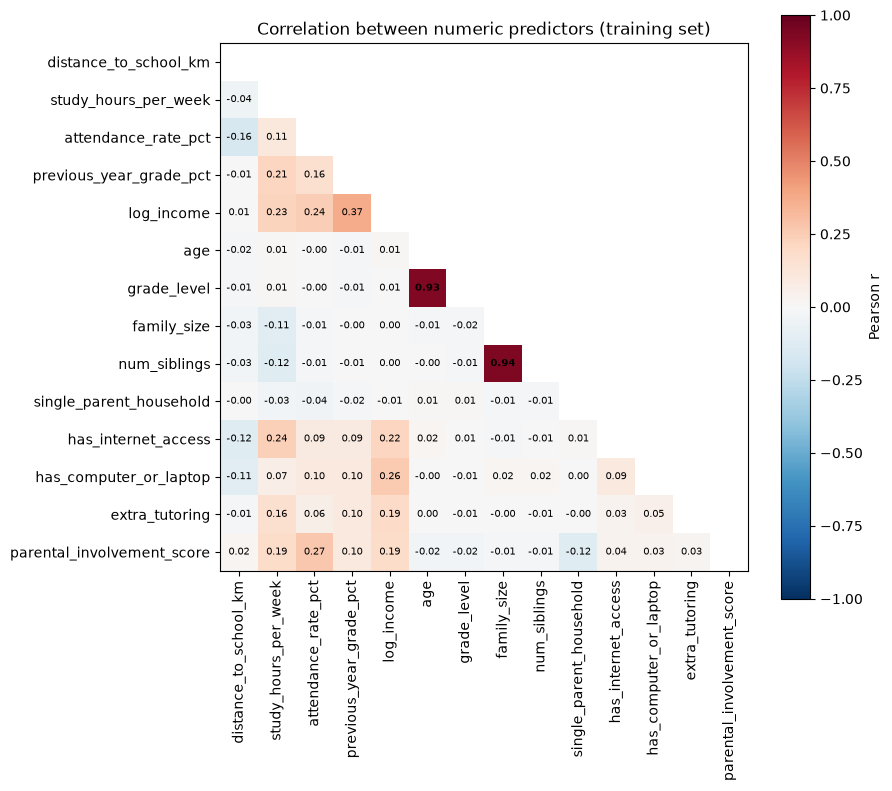

pairs above threshold: [('grade_level', 'age'), ('num_siblings', 'family_size')]
dropped for correlation: ['grade_level', 'num_siblings']


In [46]:
import matplotlib.pyplot as plt

CORR_THRESHOLD = 0.8

num_corr = X_train[NUMERIC_COLS].corr()
lower = num_corr.mask(np.triu(np.ones_like(num_corr, dtype=bool)))

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(lower.values, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(NUMERIC_COLS)), NUMERIC_COLS, rotation=90)
ax.set_yticks(range(len(NUMERIC_COLS)), NUMERIC_COLS)
for i in range(len(NUMERIC_COLS)):
    for j in range(i):
        r = num_corr.iloc[i, j]
        ax.text(j, i, f'{r:.2f}', ha='center', va='center', fontsize=7,
                fontweight='bold' if abs(r) > CORR_THRESHOLD else 'normal')
fig.colorbar(im, ax=ax, label='Pearson r')
ax.set_title('Correlation between numeric predictors (training set)')
plt.tight_layout()
plt.show()

assoc_with_target = X_train[NUMERIC_COLS].corrwith(Y_train).abs()
high_pairs = [(a, b) for i, a in enumerate(NUMERIC_COLS) for b in NUMERIC_COLS[:i]
              if abs(num_corr.loc[a, b]) > CORR_THRESHOLD]

CORR_DROP = set()
for a, b in high_pairs:
    if a not in CORR_DROP and b not in CORR_DROP:
        CORR_DROP.add(a if assoc_with_target[a] < assoc_with_target[b] else b)

print('pairs above threshold:', high_pairs)
print('dropped for correlation:', sorted(CORR_DROP))

## Filter 2: significance tests

For each predictor that survived the correlation screen, a joint F-test asks whether all of its columns together improve an OLS fit, at the 0.05 level. Testing the whole variable avoids dropping single levels of a categorical variable.

This runs on all training rows, so it is a selection step outside cross-validation. The cross-validated scores of the reduced model are therefore slightly optimistic.

In [47]:
from statsmodels.api import OLS, add_constant

SIGNIFICANCE_LEVEL = 0.05

def source_variable(col):
    for raw in PREDICTOR_COLS:
        if col == raw or col.startswith(raw + '_'):
            return raw
    return col

CANDIDATE_PREDICTORS = [p for p in PREDICTOR_COLS if p not in CORR_DROP]
CANDIDATE_COLS = [c for c in X_train.columns if source_variable(c) in CANDIDATE_PREDICTORS]
X_candidates = X_train[CANDIDATE_COLS].astype(float)

full_ols = OLS(Y_train, add_constant(X_candidates)).fit()

sig_rows = []
for raw in CANDIDATE_PREDICTORS:
    cols = [c for c in CANDIDATE_COLS if source_variable(c) == raw]
    reduced = OLS(Y_train, add_constant(X_candidates.drop(columns=cols))).fit()
    F, p, _ = full_ols.compare_f_test(reduced)
    sig_rows.append({'predictor': raw, 'n_columns': len(cols), 'F': F, 'p_value': p})

significance = pd.DataFrame(sig_rows).set_index('predictor').sort_values('p_value')
significance['keep'] = significance['p_value'] < SIGNIFICANCE_LEVEL
print(significance.round(4).to_string())

SELECTED_PREDICTORS = significance[significance['keep']].index.tolist()
SELECTED_COLS = [c for c in CANDIDATE_COLS if source_variable(c) in SELECTED_PREDICTORS]

X_train_sel = X_train[SELECTED_COLS]
X_test_sel = X_test[SELECTED_COLS]
print(f'kept {len(SELECTED_PREDICTORS)} of {len(PREDICTOR_COLS)} predictors ({len(SELECTED_COLS)} encoded columns)')

                            n_columns          F  p_value   keep
predictor                                                       
previous_year_grade_pct             1  1234.6151   0.0000   True
scholarship_status                  2    32.1815   0.0000   True
study_hours_per_week                1    57.8443   0.0000   True
has_internet_access                 1    39.0137   0.0000   True
father_education_level              6     8.8875   0.0000   True
has_computer_or_laptop              1    36.8586   0.0000   True
mother_education_level              6     8.1918   0.0000   True
attendance_rate_pct                 1    25.7474   0.0000   True
extra_tutoring                      1    11.4537   0.0007   True
log_income                          1     9.4767   0.0021   True
single_parent_household             1     9.4192   0.0022   True
family_size                         1     8.6815   0.0032   True
father_occupation                   6     2.2180   0.0385   True
age                      

## Cross-validated Lasso pipeline

The folds are defined once on the training rows (10-fold, shuffled, fixed seed). Scaling is part of the model pipeline, so each fold scales using its own training rows only, and validation rows never influence the preprocessing. The penalty alpha is chosen by grid search over these folds. The test set is not used here.

In [48]:
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

N_SPLITS = 10
ALPHA_GRID = np.logspace(-4, 1, 60)

folds = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_train_sel))

# Continuous and discrete columns (including 0/1 flags) are scaled. One-hot dummy columns pass through unchanged.
SCALE_COLS = [c for c in SELECTED_COLS if source_variable(c) in NUMERIC_COLS]

def make_lasso_pipeline():
    scaling = ColumnTransformer([('scale', StandardScaler(), SCALE_COLS)],
                                remainder='passthrough', verbose_feature_names_out=False)
    return make_pipeline(scaling.set_output(transform='pandas'), Lasso(max_iter=20000))

lasso_search = GridSearchCV(make_lasso_pipeline(), {'lasso__alpha': ALPHA_GRID},
                            cv=folds, scoring='neg_root_mean_squared_error').fit(X_train_sel, Y_train)

best_alpha = lasso_search.best_params_['lasso__alpha']
print(f'CV-selected alpha: {best_alpha:.4f}  CV RMSE: {-lasso_search.best_score_:.3f}')

# One-standard-error penalty: the largest alpha whose CV error is within 1 SE of the best
grid_mean = -lasso_search.cv_results_['mean_test_score']
grid_se = lasso_search.cv_results_['std_test_score'] / np.sqrt(N_SPLITS)
best_idx = np.argmin(grid_mean)
ALPHA_1SE = ALPHA_GRID[grid_mean <= grid_mean[best_idx] + grid_se[best_idx]].max()
print(f'alpha at 1-SE: {ALPHA_1SE:.4f}')

CV-selected alpha: 0.0023  CV RMSE: 9.585
alpha at 1-SE: 0.2019


## Lasso coefficients on all predictors (before filtering)

Lasso coefficients at the 1-SE penalty on all encoded columns from the significance tests, before the Lasso filter below removes anything. Numeric predictors are standardised, so their coefficient is the change in final grade (percentage points) for a 1 SD increase. Dummy coefficients are the difference from the reference level. Levels with a zero coefficient are the ones Lasso has dropped, and they appear as empty rows at the bottom.

levels zeroed: ['father_education_level_Doctorate', 'father_education_level_Higher Secondary', "father_education_level_Master's Degree", 'father_education_level_No Formal Education', 'father_education_level_Primary', 'father_education_level_Secondary', 'mother_education_level_Doctorate', 'mother_education_level_Higher Secondary', "mother_education_level_Master's Degree", 'mother_education_level_No Formal Education', 'mother_education_level_Primary', 'mother_education_level_Secondary', 'father_occupation_Clerical / Service', 'father_occupation_Managerial / Executive', 'father_occupation_Professional', 'father_occupation_Skilled Labor / Trade', 'father_occupation_Unemployed', 'father_occupation_Unskilled Labor', 'scholarship_status_Partial']


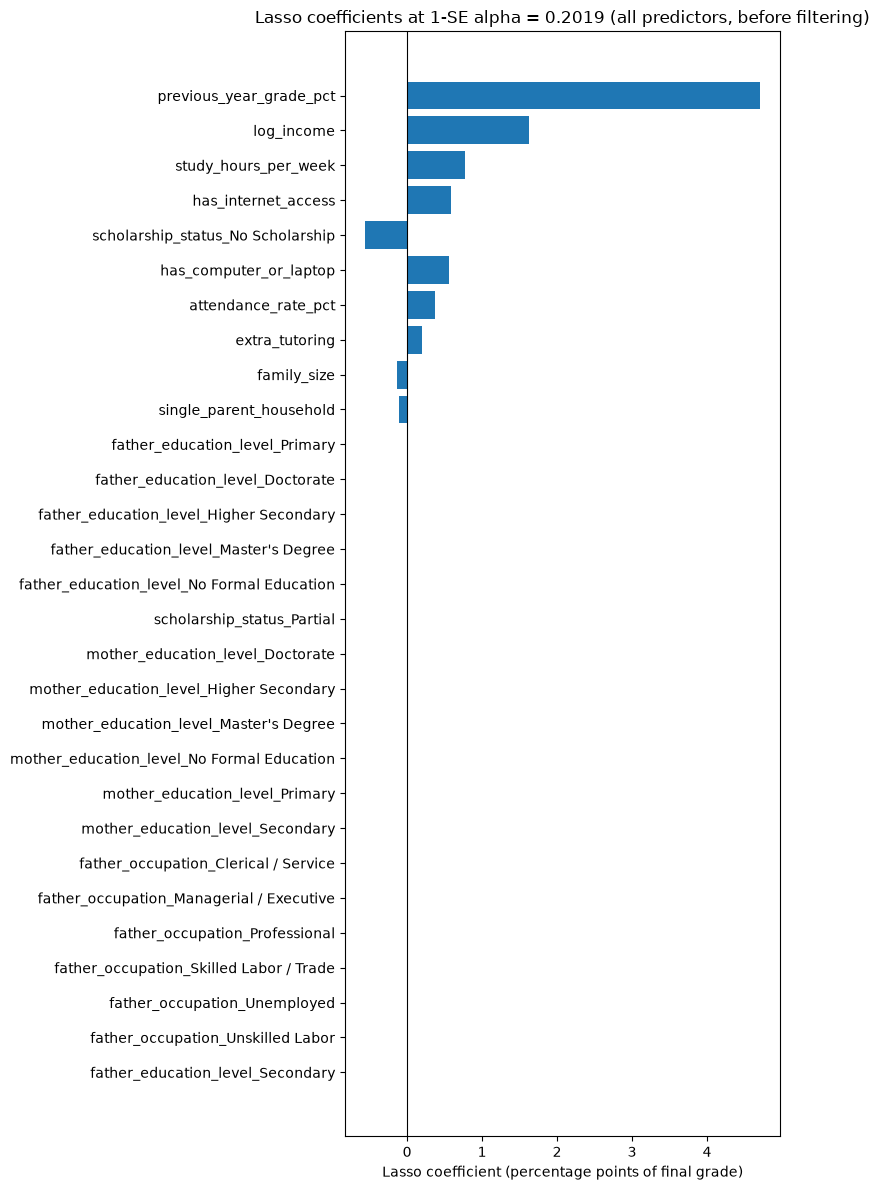

In [49]:
all_model = make_lasso_pipeline().set_params(lasso__alpha=ALPHA_1SE).fit(X_train_sel, Y_train)
lasso_coef = pd.Series(all_model[-1].coef_, index=all_model[:-1].get_feature_names_out())
print('levels zeroed:', lasso_coef[lasso_coef == 0].index.tolist())

order = lasso_coef.abs().sort_values().index
bar_colors = ['tab:blue' if lasso_coef[c] != 0 else 'lightgray' for c in order]

fig, ax = plt.subplots(figsize=(8, 12))
ax.barh(order, lasso_coef[order], color=bar_colors)
ax.axvline(0, color='black', linewidth=0.8)
ax.set_xlabel('Lasso coefficient (percentage points of final grade)')
ax.set_title(f'Lasso coefficients at 1-SE alpha = {ALPHA_1SE:.4f} (all predictors, before filtering)')
plt.tight_layout()
plt.show()

## Lasso filter (one k-fold round)

At the 1-SE penalty from the cross-validation above, each fold's Lasso is fitted on its own training rows, and we record which predictors have a non-zero coefficient. A predictor is kept if it survives in at least 5 of the 10 folds. This uses the same folds as the cross-validation and training rows only, so no validation rows influence the choice.

In [50]:
fold_support = {}
for train_idx, _ in folds:
    fold_model = clone(make_lasso_pipeline()).set_params(lasso__alpha=ALPHA_1SE)
    fold_model.fit(X_train_sel.iloc[train_idx], Y_train.iloc[train_idx])
    fold_coef = pd.Series(fold_model[-1].coef_, index=fold_model[:-1].get_feature_names_out())
    for raw in set(fold_coef[fold_coef != 0].index.map(source_variable)):
        fold_support[raw] = fold_support.get(raw, 0) + 1

support = pd.Series({p: fold_support.get(p, 0) for p in SELECTED_PREDICTORS}).sort_values(ascending=False)
KEEP_PREDICTORS = support[support >= N_SPLITS // 2].index.tolist()
DROP_PREDICTORS = [p for p in SELECTED_PREDICTORS if p not in KEEP_PREDICTORS]
print('folds (of 10) in which each predictor is non-zero:')
print(support.to_string())
print('dropped:', DROP_PREDICTORS)

FINAL_COLS = [c for c in SELECTED_COLS if source_variable(c) in KEEP_PREDICTORS]
X_train_final = X_train[FINAL_COLS]
X_test_final = X_test[FINAL_COLS]
print(f'final: {len(KEEP_PREDICTORS)} predictors ({len(FINAL_COLS)} columns)')

folds (of 10) in which each predictor is non-zero:
previous_year_grade_pct    10
scholarship_status         10
study_hours_per_week       10
has_internet_access        10
has_computer_or_laptop     10
attendance_rate_pct        10
extra_tutoring             10
log_income                 10
single_parent_household    10
family_size                10
mother_education_level      1
father_education_level      0
father_occupation           0
dropped: ['father_education_level', 'mother_education_level', 'father_occupation']
final: 10 predictors (11 columns)


## Nested cross-validation (honest estimate)

The correlation screen, significance tests, and Lasso filter are repeated inside each of 10 outer folds. Each run uses only that fold's training rows, and the selected model is scored on the held-out outer fold. For comparison, a Lasso with all predictors is tuned the same way. The earlier cross-validation scores are slightly optimistic, because the filters saw every training row. This section gives the honest estimate. The test set is not used here.

In [ ]:
from sklearn.metrics import root_mean_squared_error


def make_pipe(cols):
    scale_cols = [c for c in cols if source_variable(c) in NUMERIC_COLS]
    scaling = ColumnTransformer([('scale', StandardScaler(), scale_cols)],
                                remainder='passthrough', verbose_feature_names_out=False)
    return make_pipeline(scaling.set_output(transform='pandas'), Lasso(max_iter=20000))


def one_se_alpha(search):
    mean_rmse = -search.cv_results_['mean_test_score']
    se = search.cv_results_['std_test_score'] / np.sqrt(N_SPLITS)
    best = np.argmin(mean_rmse)
    return ALPHA_GRID[mean_rmse <= mean_rmse[best] + se[best]].max()


def select_predictors(X_tr, Y_tr):
    # Correlation screen
    num_c = X_tr[NUMERIC_COLS].corr()
    assoc = X_tr[NUMERIC_COLS].corrwith(Y_tr).abs()
    drop = set()
    for i, a in enumerate(NUMERIC_COLS):
        for b in NUMERIC_COLS[:i]:
            if abs(num_c.loc[a, b]) > CORR_THRESHOLD and a not in drop and b not in drop:
                drop.add(a if assoc[a] < assoc[b] else b)
    candidates = [p for p in PREDICTOR_COLS if p not in drop]
    cand_cols = [c for c in X_tr.columns if source_variable(c) in candidates]

    # Joint F-tests
    Xc = X_tr[cand_cols].astype(float)
    full = OLS(Y_tr, add_constant(Xc)).fit()
    kept = []
    for raw in candidates:
        cols = [c for c in cand_cols if source_variable(c) == raw]
        reduced = OLS(Y_tr, add_constant(Xc.drop(columns=cols))).fit()
        if full.compare_f_test(reduced)[1] < SIGNIFICANCE_LEVEL:
            kept.append(raw)
    sel_cols = [c for c in cand_cols if source_variable(c) in kept]

    # Inner CV for the penalty, then one fold round for the final filter
    inner = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_tr))
    search = GridSearchCV(make_pipe(sel_cols), {'lasso__alpha': ALPHA_GRID}, cv=inner,
                          scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_tr[sel_cols], Y_tr)
    alpha = one_se_alpha(search)
    support = {}
    for tr_i, _ in inner:
        m = clone(make_pipe(sel_cols)).set_params(lasso__alpha=alpha)
        m.fit(X_tr[sel_cols].iloc[tr_i], Y_tr.iloc[tr_i])
        cf = pd.Series(m[-1].coef_, index=m[:-1].get_feature_names_out())
        for raw in set(cf[cf != 0].index.map(source_variable)):
            support[raw] = support.get(raw, 0) + 1
    final_preds = [p for p in kept if support.get(p, 0) >= N_SPLITS // 2]
    return [c for c in sel_cols if source_variable(c) in final_preds], alpha


outer = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_train))
all_cols = list(X_train.columns)
rows, kept_counts = [], {}
for k, (tr_i, va_i) in enumerate(outer):
    X_tr, X_va = X_train.iloc[tr_i], X_train.iloc[va_i]
    Y_tr, Y_va = Y_train.iloc[tr_i], Y_train.iloc[va_i]

    cols, alpha = select_predictors(X_tr, Y_tr)
    selected = make_pipe(cols).set_params(lasso__alpha=alpha).fit(X_tr[cols], Y_tr)
    rmse_sel = root_mean_squared_error(Y_va, selected.predict(X_va[cols]))

    inner = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_tr))
    search = GridSearchCV(make_pipe(all_cols), {'lasso__alpha': ALPHA_GRID}, cv=inner,
                          scoring='neg_root_mean_squared_error', n_jobs=-1).fit(X_tr, Y_tr)
    everything = make_pipe(all_cols).set_params(lasso__alpha=one_se_alpha(search)).fit(X_tr, Y_tr)
    rmse_all = root_mean_squared_error(Y_va, everything.predict(X_va))

    preds = sorted(set(source_variable(c) for c in cols))
    rows.append({'outer_fold': k, 'n_predictors': len(preds),
                 'rmse_selected': rmse_sel, 'rmse_all_predictors': rmse_all})
    for raw in preds:
        kept_counts[raw] = kept_counts.get(raw, 0) + 1

nested = pd.DataFrame(rows)
print(nested.round(3).to_string(index=False))
print(f"mean outer RMSE: selected {nested['rmse_selected'].mean():.3f}, all predictors {nested['rmse_all_predictors'].mean():.3f}")
print('outer folds (of 10) in which each predictor was kept:')
print(pd.Series(kept_counts).sort_values(ascending=False).to_string())

## Model comparison (OLS, Ridge, Lasso)

All models use the 11 columns kept by the Lasso filter. Ridge and Lasso penalties are tuned by an inner 10-fold CV. Cross-validated RMSE comes from an outer 10-fold CV on the training set, which uses the same folds as the Lasso filter. Each model is then refitted on all training rows and scored once on the test set. A mean-only baseline is included for reference. This is the first time the test set is used.

In [ ]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import cross_val_score

RIDGE_GRID = np.logspace(-3, 3, 50)

def scaled_model(cols, estimator):
    scale_cols = [c for c in cols if source_variable(c) in NUMERIC_COLS]
    scaling = ColumnTransformer([('scale', StandardScaler(), scale_cols)],
                                remainder='passthrough', verbose_feature_names_out=False)
    return make_pipeline(scaling.set_output(transform='pandas'), estimator)

inner_cv = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
outer_folds = list(KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED).split(X_train_final))
FINAL_COLS_LIST = list(X_train_final.columns)

models = {
    'Mean only (baseline)': DummyRegressor(strategy='mean'),
    'OLS': scaled_model(FINAL_COLS_LIST, LinearRegression()),
    'Ridge': GridSearchCV(scaled_model(FINAL_COLS_LIST, Ridge()), {'ridge__alpha': RIDGE_GRID},
                          cv=inner_cv, scoring='neg_root_mean_squared_error', n_jobs=-1),
    'Lasso': GridSearchCV(scaled_model(FINAL_COLS_LIST, Lasso(max_iter=20000)), {'lasso__alpha': ALPHA_GRID},
                          cv=inner_cv, scoring='neg_root_mean_squared_error', n_jobs=-1),
}

rows = []
for name, model in models.items():
    cv_rmse = -cross_val_score(model, X_train_final, Y_train, cv=outer_folds,
                               scoring='neg_root_mean_squared_error', n_jobs=-1)
    model.fit(X_train_final, Y_train)
    test_rmse = root_mean_squared_error(Y_test, model.predict(X_test_final))
    rows.append({'model': name, 'cv_rmse': cv_rmse.mean(), 'cv_rmse_sd': cv_rmse.std(),
                 'test_rmse': test_rmse})
    if hasattr(model, 'best_params_'):
        print(name, 'alpha chosen on full training set:', round(list(model.best_params_.values())[0], 4))

comparison = pd.DataFrame(rows).set_index('model')
print(comparison.round(3).to_string())